<a href="https://colab.research.google.com/github/brayent557-creator/Tugas-Analisis-Eksplorasi-Data/blob/main/AED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:



import pandas as pd
import numpy as np
from sklearn.datasets import load_iris

# Mengambil dataset Iris
iris = load_iris()

# Mengubah data menjadi tabel
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Mengambil 100 sampel secara acak
data = df.sample(n=100, random_state=42)

# Mengambil variabel panjang kelopak
sampel = data["petal length (cm)"]

# Menampilkan data
print("Jumlah sampel:", len(sampel))
print(sampel)

Jumlah sampel: 100
73     4.7
18     1.7
118    6.9
78     4.5
76     4.8
      ... 
89     4.0
8      1.4
13     1.1
119    5.0
125    6.0
Name: petal length (cm), Length: 100, dtype: float64


In [ ]:


# Menghitung estimasi titik dan interval Z

n = len(sampel)
rata_rata = np.mean(sampel)
standar_deviasi = np.std(sampel, ddof=1)

# Standard error
SE = standar_deviasi / np.sqrt(n)

# Nilai Z untuk tingkat kepercayaan 95%
Z = 1.96

# Menghitung batas interval
batas_bawah = rata_rata - (Z * SE)
batas_atas = rata_rata + (Z * SE)

print("Jumlah sampel:", n)
print("Estimasi titik (Mean):", rata_rata)
print("Standar deviasi:", standar_deviasi)
print("Standard Error:", SE)
print("Nilai Z:", Z)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)
print("Interval kepercayaan 95%:",
      (batas_bawah, batas_atas))

Jumlah sampel: 100
Estimasi titik (Mean): 3.635
Standar deviasi: 1.8029927421603305
Standard Error: 0.18029927421603303
Nilai Z: 1.96
Batas bawah: 3.281613422536575
Batas atas: 3.9883865774634244
Interval kepercayaan 95%: (np.float64(3.281613422536575), np.float64(3.9883865774634244))


In [ ]:


# RESAMPLING METODE JACKKNIFE

n = len(sampel)
jackknife_means = []

for i in range(n):
    data_jackknife = sampel.drop(sampel.index[i])
    rata_jackknife = np.mean(data_jackknife)
    jackknife_means.append(rata_jackknife)

# Rata-rata hasil Jackknife
mean_jackknife = np.mean(jackknife_means)

# Menghitung standard error Jackknife
se_jackknife = np.sqrt(
    (n-1)/n * np.sum(
        (np.array(jackknife_means) - mean_jackknife)**2
    )
)

print("Jumlah resampling Jackknife:", len(jackknife_means))
print("Rata-rata Jackknife:", mean_jackknife)
print("Standard Error Jackknife:", se_jackknife)

Jumlah resampling Jackknife: 100
Rata-rata Jackknife: 3.6350000000000007
Standard Error Jackknife: 0.18029927421603334


In [ ]:


# RESAMPLING METODE BOOTSTRAPPING

bootstrap_means = []

for i in range(1000):
    data_bootstrap = sampel.sample(
        n=len(sampel),
        replace=True,
        random_state=i
    )

    rata_bootstrap = np.mean(data_bootstrap)
    bootstrap_means.append(rata_bootstrap)

# Rata-rata hasil Bootstrap
mean_bootstrap = np.mean(bootstrap_means)

print("Jumlah iterasi:", len(bootstrap_means))
print("Rata-rata Bootstrap:", mean_bootstrap)
print("Standar deviasi Bootstrap:", np.std(bootstrap_means, ddof=1))

Jumlah iterasi: 1000
Rata-rata Bootstrap: 3.641569
Standar deviasi Bootstrap: 0.17307016646875198


PERBANDINGAN RATA-RATA


,Metode,Rata-rata
0,Estimasi Titik,3.635000
1,Jackknife,3.635000
2,Bootstrap,3.641569


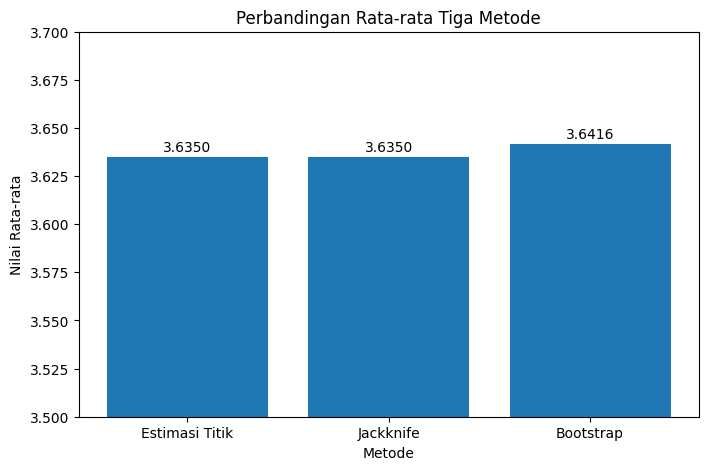

In [ ]:


import pandas as pd
import matplotlib.pyplot as plt

# Membuat tabel perbandingan
perbandingan = pd.DataFrame({
    "Metode": [
        "Estimasi Titik",
        "Jackknife",
        "Bootstrap"
    ],
    "Rata-rata": [
        rata_rata,
        mean_jackknife,
        mean_bootstrap
    ]
})

# Menampilkan tabel
print("PERBANDINGAN RATA-RATA")
display(perbandingan.round(6))

# Membuat grafik batang
plt.figure(figsize=(8, 5))
plt.bar(
    perbandingan["Metode"],
    perbandingan["Rata-rata"]
)

plt.title("Perbandingan Rata-rata Tiga Metode")
plt.xlabel("Metode")
plt.ylabel("Nilai Rata-rata")
plt.ylim(3.5, 3.7)

# Menampilkan nilai di atas batang
for i, nilai in enumerate(perbandingan["Rata-rata"]):
    plt.text(i, nilai + 0.003, f"{nilai:.4f}", ha="center")

plt.show()

# Bagian Baru

# Bagian Baru